#### **Libraries and modules**

In [12]:
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from pathlib import Path
from datetime import datetime
from cmcrameri import cm as cmc

#### **Load AIFS-ENS and ERA5 data**

In [13]:
# Load AIFS dataset
AIFS_filename_pl = "AIFS-ENS_02_Foehn_SouthAmerica_pl_2025-11-17_18UTC.nc"
ds_AIFS_pl = xr.open_dataset(AIFS_filename_pl)

# Load ERA5 dataset
ERA5_filename_pl = "ERA5_02_Foehn_SouthAmerica_pl_2025-11-17_18UTC.nc"
ds_ERA5_pl = xr.open_dataset(ERA5_filename_pl)


#### **Convert geopotential to geopotential height in decametres (dam) in the xarray dataset**

In [14]:
# Standard acceleration due to gravity
earth_gravity = 9.80665  # m s^-2

# Geopotential height at pressure levels AIFS
# Convert geopotential from m^2 s^-2 to decametres
ds_AIFS_pl["geopotential_height_in_dam"] = (
    ds_AIFS_pl["z"]
    / earth_gravity
    / 10.0
)

ds_AIFS_pl["geopotential_height_in_dam"].attrs = {
    "long_name": "Geopotential Height",
    "units": "dam",
    "standard_name": "geopotential_height"
}

# Geopotential height at pressure levels ERA5
# Convert geopotential from m^2 s^-2 to decametres
ds_ERA5_pl["geopotential_height_in_dam"] = (
    ds_ERA5_pl["z"]
    / earth_gravity
    / 10.0
)

ds_ERA5_pl["geopotential_height_in_dam"].attrs = {
    "long_name": "Geopotential Height",
    "units": "dam",
    "standard_name": "geopotential_height"
}

#### **Select the target time (valid time of forecast)**

In [15]:
target_time = pd.to_datetime("2025-11-17_18UTC", format="%Y-%m-%d_%HUTC")

#### **Locate minimum Z500 in ERA5**

In [16]:
# Minimum Z500 in ERA5
geopotential_height_min_500hPa_ERA5_pl = (
    ds_ERA5_pl["geopotential_height_in_dam"]
    .sel(
        isobaricInhPa=500,
        method="nearest"
    )
    .squeeze()
)

# Find the index of the minimum
min_flat_idx = int(
    np.nanargmin(
        geopotential_height_min_500hPa_ERA5_pl.values
    )
)

min_idx = np.unravel_index(
    min_flat_idx,
    geopotential_height_min_500hPa_ERA5_pl.shape
)

lat_min_500hPa_ERA5_pl = float(
    geopotential_height_min_500hPa_ERA5_pl.latitude.values[
        min_idx[0]
    ]
)

lon_min_500hPa_ERA5_pl = float(
    geopotential_height_min_500hPa_ERA5_pl.longitude.values[
        min_idx[1]
    ]
)

# Extract the scalar minimum Z500 value
geopotential_height_min_500hPa_ERA5_pl_value = float(
    geopotential_height_min_500hPa_ERA5_pl.values[
        min_idx
    ]
)

print(
    "ERA5 minimum Z500: "
    f"{geopotential_height_min_500hPa_ERA5_pl_value:.2f} dam"
)

print(
    "Location (lat, lon): "
    f"({lat_min_500hPa_ERA5_pl:.2f}, "
    f"{lon_min_500hPa_ERA5_pl:.2f})"
)

ERA5 minimum Z500: 500.46 dam
Location (lat, lon): (-56.25, -71.00)


#### **Subset AIFS Z500 at the location of the ERA5 minimum**

In [17]:
# Convert longitude from ERA5 to the AIFS convention
# of 0° to 360°
lon_min_aifs_500pl = (
    lon_min_500hPa_ERA5_pl % 360
)

# Find the closest forecast time in AIFS to the target time
target_time = np.datetime64(
    "2025-11-17T18:00:00"
)

lead_idx = int(
    np.argmin(
        np.abs(
            ds_AIFS_pl["fc_valid_time"].values
            - target_time
        )
    )
)

lead_sel = ds_AIFS_pl[
    "leadtime"
].values[lead_idx]

# Extract Z500 at the ERA5 minimum location for that lead time
aifs_z500_extreme_loc = (
    ds_AIFS_pl["geopotential_height_in_dam"]
    .sel(
        isobaricInhPa=500,
        latitude=lat_min_500hPa_ERA5_pl,
        longitude=lon_min_aifs_500pl,
        leadtime=lead_sel,
        method="nearest"
    )
)

# Select the nearest AIFS grid point at the ERA5 Z500 minimum
# location for that lead time
aifs_point = ds_AIFS_pl.sel(
    isobaricInhPa=500,
    latitude=lat_min_500hPa_ERA5_pl,
    longitude=lon_min_aifs_500pl,
    leadtime=lead_sel,
    method="nearest"
)

# Select AIFS Z500 at the ERA5 minimum location for all
# lead times and ensemble members
ds_AIFS_pl_sel_z500 = (
    ds_AIFS_pl["geopotential_height_in_dam"]
    .sel(
        isobaricInhPa=500,
        latitude=lat_min_500hPa_ERA5_pl,
        longitude=lon_min_aifs_500pl,
        method="nearest"
    )
)

## **Plotting**

#### **Set output directory for all plots**

In [18]:
# Default output directory for all plots
PLOT_DIR = Path(
    r"C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc"
    r"\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks"
    r"\01_Case_Study\01_Code\01_Plots\04_Z500"
)

def save_plot(
    fig,
    plot_name,
    output_dir=PLOT_DIR,
    dpi=300
):
    """
    Save a Matplotlib figure as both PNG and PDF.

    PNG files are saved in:
        output_dir/01_png

    PDF files are saved in:
        output_dir/02_pdf

    Files are named:
        YYYYMMDD_Z500_plot_name.png
        YYYYMMDD_Z500_plot_name.pdf
    """

    output_dir = Path(output_dir)

    # Separate output directories
    png_dir = output_dir / "01_png"
    pdf_dir = output_dir / "02_pdf"

    # Create directories if they do not already exist
    png_dir.mkdir(parents=True, exist_ok=True)
    pdf_dir.mkdir(parents=True, exist_ok=True)

    current_date = datetime.now().strftime("%Y%m%d")

    # Prevent unwanted spaces in filenames
    clean_plot_name = plot_name.strip().replace(" ", "_")

    filename = (
        f"{current_date}_Z500_"
        f"{clean_plot_name}"
    )

    png_path = png_dir / f"{filename}.png"
    pdf_path = pdf_dir / f"{filename}.pdf"

    # High-resolution raster image
    fig.savefig(
        png_path,
        dpi=dpi,
        bbox_inches="tight"
    )

    # Vector image
    fig.savefig(
        pdf_path,
        bbox_inches="tight"
    )

    print(
        "Plots saved as:\n"
        f"PNG: {png_path}\n"
        f"PDF: {pdf_path}"
    )

    return png_path, pdf_path

### **Boxplots**

#### **Boxplot comparing AIFS ensemble Z500 with minimum Z500 in ERA5**

Plots saved as:
PNG: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\04_Z500\01_png\20260723_Z500_boxplot_AIFS_ERA5_min.png
PDF: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\04_Z500\02_pdf\20260723_Z500_boxplot_AIFS_ERA5_min.pdf


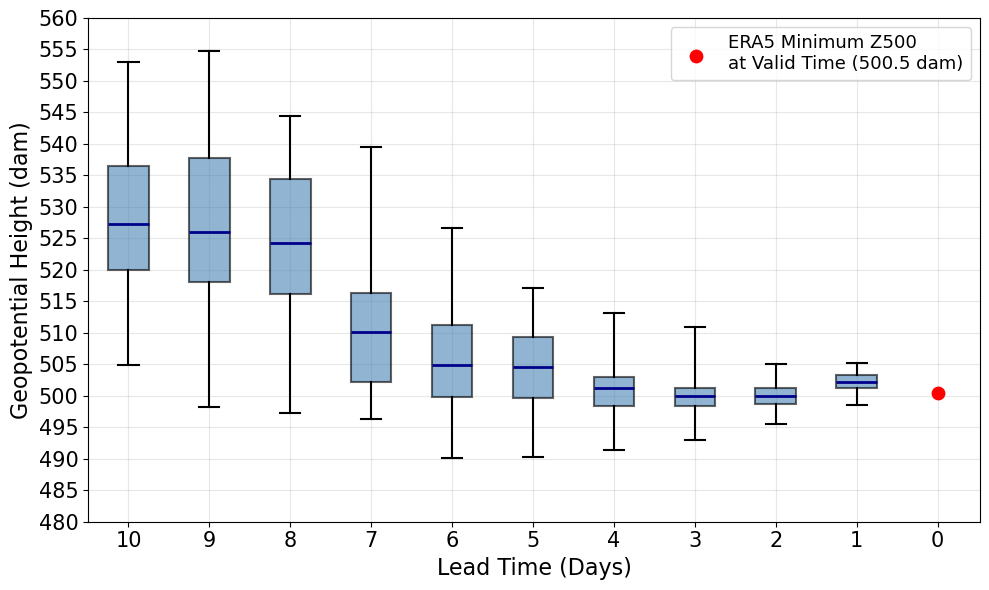

In [19]:
fig, ax = plt.subplots(figsize=(10, 6))

leadtimes = np.arange(1, 10 + 1, 1)
n_leads = len(leadtimes)

# Reverse data so lead time 10 days appears first
data_reversed = (
    ds_AIFS_pl_sel_z500.values[:, ::-1]
)

box = ax.boxplot(
    data_reversed,
    positions=np.arange(1, n_leads + 1),
    whis=[0, 100],
    showfliers=False,
    patch_artist=True,
    boxprops=dict(
        facecolor="steelblue",
        alpha=0.6,
        linewidth=1.5
    ),
    medianprops=dict(
        color="darkblue",
        linewidth=2
    ),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5)
)

# ERA5 point: minimum Z500
ax.scatter(
    n_leads + 1,
    geopotential_height_min_500hPa_ERA5_pl_value,
    color="red",
    marker="o",
    s=80,
    zorder=5,
    label=(
        "ERA5 Minimum Z500\n"
        f"at Valid Time "
        f"({geopotential_height_min_500hPa_ERA5_pl_value:.1f} "
        "dam)"
    )
)

# Tick labels
xtick_positions = np.arange(1, n_leads + 2)
xtick_labels = list(leadtimes[::-1]) + [0]

ax.set_xticks(xtick_positions)
ax.set_xticklabels(xtick_labels, fontsize=15)
ax.tick_params(axis="y", labelsize=15)

valid_time = pd.to_datetime(
    ds_AIFS_pl_sel_z500[
        "fc_valid_time"
    ].values[0]
)

time_str = valid_time.strftime(
    "%Y-%m-%d %H:%M"
)

ax.set_xlabel(
    "Lead Time (Days)",
    fontsize=16
)

ax.set_ylabel(
    "Geopotential Height (dam)",
    fontsize=16
)

# Fixed y-axis limits
ax.set_ylim(
    480,
    560
)

ax.set_yticks(
    np.arange(
        480,
        560 + 0.1,
        5
    )
)

ax.legend(
    fontsize=13,
    loc="upper right"
)

ax.set_axisbelow(True)
ax.grid(alpha=0.3)

fig.tight_layout()

png_path, pdf_path = save_plot(
    fig,
    "boxplot_AIFS_ERA5_min"
)

plt.show()
plt.close(fig)

#### **Boxplot comparing AIFS ensemble Z500 with minimum Z500 in ERA5 with spatial shift allowance – AIFS finds minimum Z500 within ±2.0° latitude and ±2.0° longitude of the ERA5 minimum location**

Plots saved as:
PNG: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\04_Z500\01_png\20260723_Z500_boxplot_AIFS_ERA5_min_spatial_allowance.png
PDF: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\04_Z500\02_pdf\20260723_Z500_boxplot_AIFS_ERA5_min_spatial_allowance.pdf


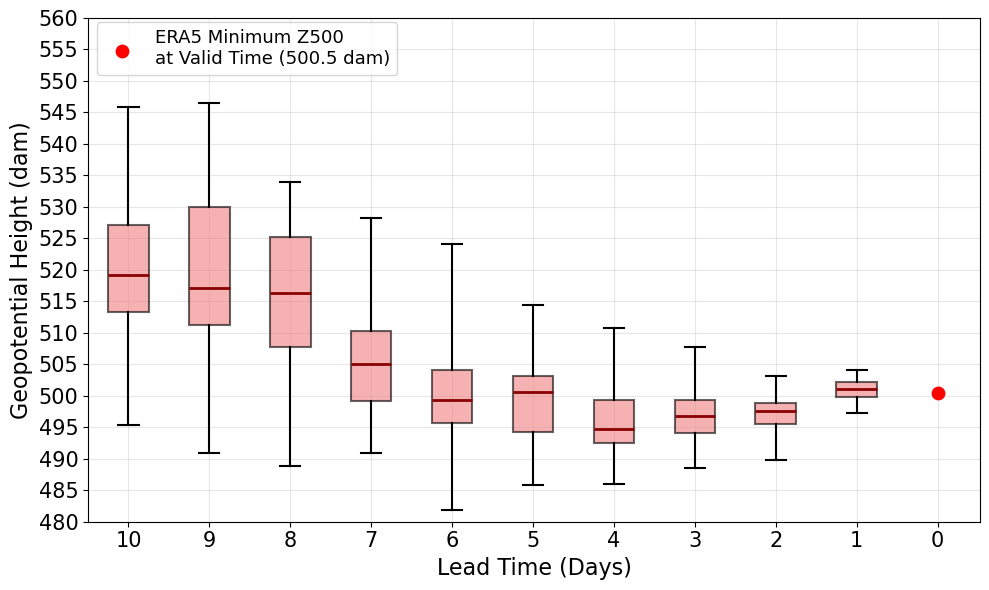

In [20]:
# Define search window around the ERA5 Z500 minimum
search_radius_lat = 2.0  # ±2.0° latitude
search_radius_lon = 2.0  # ±2.0° longitude

lat_center = lat_min_500hPa_ERA5_pl
lon_center = lon_min_500hPa_ERA5_pl % 360

lat_min = lat_center - search_radius_lat
lat_max = lat_center + search_radius_lat

# Select Z500
ds_AIFS_Z500 = (
    ds_AIFS_pl["geopotential_height_in_dam"]
    .sel(
        isobaricInhPa=500,
        method="nearest"
    )
)

# Circular longitude distance, robust around 0°/360°
lon_distance = np.abs(
    (
        (
            ds_AIFS_Z500[
                "longitude"
            ]
            - lon_center
            + 180
        )
        % 360
    )
    - 180
)

# Extract Z500 within the search window for all ensemble
# members and lead times
ds_AIFS_Z500_search_window = (
    ds_AIFS_Z500.where(
        (
            (
                ds_AIFS_Z500[
                    "latitude"
                ]
                >= lat_min
            )
            & (
                ds_AIFS_Z500[
                    "latitude"
                ]
                <= lat_max
            )
            & (
                lon_distance
                <= search_radius_lon
            )
        ),
        drop=True
    )
)

# Find minimum Z500 within the search window for each
# ensemble member and lead time
aifs_Z500_min_in_window = (
    ds_AIFS_Z500_search_window.min(
        dim=[
            "latitude",
            "longitude"
        ]
    )
)

fig, ax = plt.subplots(figsize=(10, 6))

# Use the actual lead-time coordinate
leadtimes = (
    aifs_Z500_min_in_window[
        "leadtime"
    ].values
)

n_leads = len(leadtimes)

# Convert lead-time labels to days when stored as timedelta64
if np.issubdtype(
    leadtimes.dtype,
    np.timedelta64
):
    leadtime_days = (
        leadtimes
        / np.timedelta64(1, "D")
    ).astype(int)

else:
    leadtime_days = (
        leadtimes.astype(int)
    )

# Build one array per lead time, with longest lead time first
data_for_boxplot = []

for lt in leadtimes[::-1]:
    values = np.ravel(
        aifs_Z500_min_in_window
        .sel(
            leadtime=lt
        )
        .values
    )

    # Remove possible missing values
    values = values[
        np.isfinite(values)
    ]

    data_for_boxplot.append(values)

box = ax.boxplot(
    data_for_boxplot,
    positions=np.arange(1, n_leads + 1),
    whis=[0, 100],
    showfliers=False,
    patch_artist=True,
    boxprops=dict(
        facecolor="lightcoral",
        alpha=0.6,
        linewidth=1.5
    ),
    medianprops=dict(
        color="darkred",
        linewidth=2
    ),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5)
)

# ERA5 point: minimum Z500
ax.scatter(
    n_leads + 1,
    geopotential_height_min_500hPa_ERA5_pl_value,
    color="red",
    marker="o",
    s=80,
    zorder=5,
    label=(
        "ERA5 Minimum Z500\n"
        f"at Valid Time "
        f"({geopotential_height_min_500hPa_ERA5_pl_value:.1f} "
        "dam)"
    )
)

# Tick labels
xtick_positions = np.arange(1, n_leads + 2)
xtick_labels = (
    list(
        leadtime_days[::-1]
    )
    + [0]
)

ax.set_xticks(
    xtick_positions
)

ax.set_xticklabels(
    xtick_labels,
    fontsize=15
)

ax.tick_params(
    axis="y",
    labelsize=15
)

valid_time = pd.to_datetime(
    aifs_Z500_min_in_window[
        "fc_valid_time"
    ].values[0]
)

time_str = valid_time.strftime(
    "%Y-%m-%d %H:%M"
)

ax.set_xlabel(
    "Lead Time (Days)",
    fontsize=16
)

ax.set_ylabel(
    "Geopotential Height (dam)",
    fontsize=16
)

# Fixed y-axis limits
ax.set_ylim(
    480,
    560
)

ax.set_yticks(
    np.arange(
        480,
        560 + 0.1,
        5
    )
)

ax.legend(
    fontsize=13,
    loc="upper left",
    bbox_to_anchor=(0.0, 1.01)
)

ax.set_axisbelow(True)
ax.grid(alpha=0.3)

fig.tight_layout()

png_path, pdf_path = save_plot(
    fig,
    "boxplot_AIFS_ERA5_min_spatial_allowance"
)

plt.show()
plt.close(fig)

#### **Difference plot for Z500**

Plots saved as:
PNG: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\04_Z500\01_png\20260723_Z500_difference_plot_AIFS_ERA5_leadtimes.png
PDF: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\04_Z500\02_pdf\20260723_Z500_difference_plot_AIFS_ERA5_leadtimes.pdf


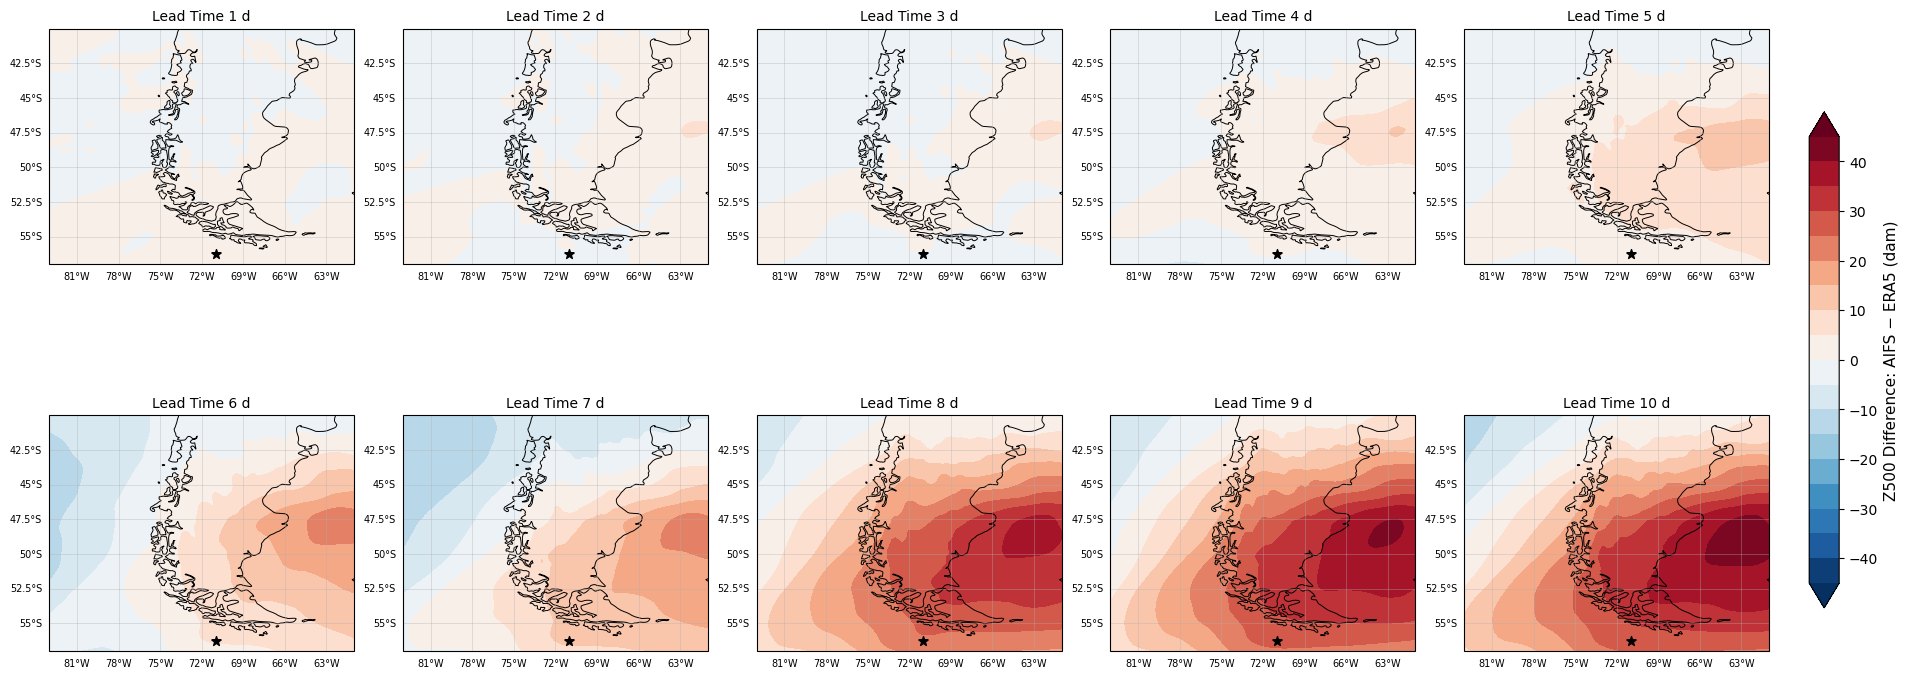

In [21]:
# Z500 difference:
# AIFS ensemble mean minus ERA5
#
# Blue: AIFS ensemble mean is lower than ERA5
# Red:  AIFS ensemble mean is higher than ERA5

# ------------------------------------------------------------------
# Use the exact same spatial extent as the other difference plots
# ------------------------------------------------------------------

common_lat_min_Z500_diff = -57.0
common_lat_max_Z500_diff = -40.0
common_lon_min_Z500_diff = 277.0
common_lon_max_Z500_diff = 299.0

# ------------------------------------------------------------------
# Select the AIFS Z500 field on the common map domain
# ------------------------------------------------------------------

ds_AIFS_Z500_diff = (
    ds_AIFS_pl["geopotential_height_in_dam"]
    .sel(
        isobaricInhPa=500,
        method="nearest"
    )
    .sel(
        latitude=slice(
            common_lat_max_Z500_diff,
            common_lat_min_Z500_diff
        ),
        longitude=slice(
            common_lon_min_Z500_diff,
            common_lon_max_Z500_diff
        )
    )
)

# ------------------------------------------------------------------
# AIFS ensemble mean
# ------------------------------------------------------------------

aifs_Z500_ens_mean_diff = (
    ds_AIFS_Z500_diff
    .mean(dim="ensemble_members")
    .sortby("leadtime")
    .squeeze(drop=True)
)

# ------------------------------------------------------------------
# Prepare ERA5 Z500
# ------------------------------------------------------------------

era5_Z500_diff = (
    ds_ERA5_pl["geopotential_height_in_dam"]
    .sel(
        isobaricInhPa=500,
        method="nearest"
    )
    .squeeze(drop=True)
    .assign_coords(
        longitude=(
            ds_ERA5_pl[
                "longitude"
            ]
            % 360
        )
    )
    .sortby("latitude")
    .sortby("longitude")
)

# ERA5 field on the displayed domain
era5_Z500_domain_diff = (
    era5_Z500_diff.where(
        (
            (
                era5_Z500_diff.latitude
                >= common_lat_min_Z500_diff
            )
            & (
                era5_Z500_diff.latitude
                <= common_lat_max_Z500_diff
            )
            & (
                era5_Z500_diff.longitude
                >= common_lon_min_Z500_diff
            )
            & (
                era5_Z500_diff.longitude
                <= common_lon_max_Z500_diff
            )
        ),
        drop=True
    )
)

# ------------------------------------------------------------------
# Interpolate ERA5 onto the AIFS grid
# ------------------------------------------------------------------

era5_Z500_on_aifs_diff = (
    era5_Z500_diff.interp(
        latitude=aifs_Z500_ens_mean_diff.latitude,
        longitude=aifs_Z500_ens_mean_diff.longitude
    )
)

# ------------------------------------------------------------------
# Calculate AIFS ensemble-mean minus ERA5 Z500 difference
# ------------------------------------------------------------------

Z500_difference = (
    aifs_Z500_ens_mean_diff
    - era5_Z500_on_aifs_diff
).transpose(
    "leadtime",
    "latitude",
    "longitude"
)

Z500_difference.name = (
    "Z500_difference"
)

# Check that the interpolation produced valid values
n_finite_Z500_difference_values = int(
    np.isfinite(
        Z500_difference.values
    ).sum()
)

if n_finite_Z500_difference_values == 0:
    raise ValueError(
        "The ERA5-to-AIFS interpolation produced no "
        "finite values. Check the latitude and longitude "
        "coordinates."
    )

# ------------------------------------------------------------------
# Find the ERA5 minimum Z500 within the displayed domain
# ------------------------------------------------------------------

era5_Z500_stacked_diff = (
    era5_Z500_domain_diff.stack(
        gridpoint=(
            "latitude",
            "longitude"
        )
    )
)

era5_Z500_min_index_diff = int(
    era5_Z500_stacked_diff.argmin(
        dim="gridpoint",
        skipna=True
    ).values
)

era5_Z500_min_point_diff = (
    era5_Z500_stacked_diff.isel(
        gridpoint=era5_Z500_min_index_diff
    )
)

era5_Z500_min_value_diff = float(
    era5_Z500_min_point_diff.values
)

era5_Z500_min_lat_diff = float(
    era5_Z500_min_point_diff[
        "latitude"
    ].values
)

era5_Z500_min_lon_diff = float(
    era5_Z500_min_point_diff[
        "longitude"
    ].values
)

# ------------------------------------------------------------------
# Prepare lead-time labels
# ------------------------------------------------------------------

leadtimes_Z500_diff = (
    aifs_Z500_ens_mean_diff[
        "leadtime"
    ].values
)

n_leadtimes_Z500_diff = len(
    leadtimes_Z500_diff
)

if n_leadtimes_Z500_diff == 0:
    raise ValueError(
        "No AIFS lead times were found."
    )

if n_leadtimes_Z500_diff > 10:
    raise ValueError(
        "The 2 × 5 layout supports a maximum of "
        "10 AIFS lead times."
    )

if np.issubdtype(
    leadtimes_Z500_diff.dtype,
    np.timedelta64
):
    leadtime_days_Z500_diff = (
        leadtimes_Z500_diff
        / np.timedelta64(1, "D")
    ).astype(int)

else:
    leadtime_days_Z500_diff = (
        leadtimes_Z500_diff.astype(int)
    )

# ------------------------------------------------------------------
# Create one common symmetric Z500-difference scale
# ------------------------------------------------------------------

difference_abs_max_Z500 = float(
    np.abs(
        Z500_difference
    ).max(
        skipna=True
    ).compute().values
)

if not np.isfinite(
    difference_abs_max_Z500
):
    raise ValueError(
        "The Z500 difference contains no finite values."
    )

# Use 5 dam intervals
difference_step_Z500 = 5.0

# Round upward to the next multiple of 5 dam
difference_limit_Z500 = max(
    difference_step_Z500,
    float(
        difference_step_Z500
        * np.ceil(
            difference_abs_max_Z500
            / difference_step_Z500
        )
    )
)

difference_levels_Z500 = np.arange(
    -difference_limit_Z500,
    difference_limit_Z500
    + difference_step_Z500,
    difference_step_Z500
)

# ------------------------------------------------------------------
# Create figure: 2 rows × 5 columns
# ------------------------------------------------------------------

map_projection = ccrs.PlateCarree()

fig, axes = plt.subplots(
    2,
    5,
    figsize=(20, 8),
    subplot_kw={
        "projection": map_projection
    }
)

axes = axes.flatten()

fig.subplots_adjust(
    left=0.04,
    right=0.90,
    bottom=0.08,
    top=0.95,
    wspace=0.16,
    hspace=0.25
)

# ------------------------------------------------------------------
# Difference panels
# ------------------------------------------------------------------

for i, lt in enumerate(
    leadtimes_Z500_diff
):
    ax = axes[i]

    difference_Z500_sel = (
        Z500_difference.sel(
            leadtime=lt
        )
    )

    ax.set_extent(
        [
            common_lon_min_Z500_diff,
            common_lon_max_Z500_diff,
            common_lat_min_Z500_diff,
            common_lat_max_Z500_diff
        ],
        crs=map_projection
    )

    # Z500-difference background
    cf_Z500_diff = ax.contourf(
        difference_Z500_sel.longitude,
        difference_Z500_sel.latitude,
        difference_Z500_sel,
        levels=difference_levels_Z500,
        cmap="RdBu_r",
        extend="both",
        transform=map_projection
    )

    # ERA5 minimum-Z500 location
    ax.scatter(
        era5_Z500_min_lon_diff,
        era5_Z500_min_lat_diff,
        marker="*",
        color="black",
        s=50,
        transform=map_projection,
        zorder=6
    )

    # Coastlines
    ax.add_feature(
        cfeature.COASTLINE,
        linewidth=0.7
    )

    ax.set_title(
        f"Lead Time "
        f"{leadtime_days_Z500_diff[i]} d",
        fontsize=10
    )

    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.5,
        alpha=0.5
    )

    gl.left_labels = True
    gl.bottom_labels = True
    gl.top_labels = False
    gl.right_labels = False

    gl.xlabel_style = {
        "size": 7
    }

    gl.ylabel_style = {
        "size": 7
    }

    gl.xpadding = 5
    gl.ypadding = 5

# Hide unused panels if fewer than ten lead times exist
for panel_index in range(
    n_leadtimes_Z500_diff,
    len(axes)
):
    axes[
        panel_index
    ].set_visible(False)

# ------------------------------------------------------------------
# Shared colorbar
# ------------------------------------------------------------------

cbar_ax = fig.add_axes([
    0.92,
    0.18,
    0.015,
    0.62
])

cbar = fig.colorbar(
    cf_Z500_diff,
    cax=cbar_ax,
    boundaries=difference_levels_Z500,
    spacing="proportional",
    extend="both",
    extendfrac="auto"
)

cbar.set_label(
    "Z500 Difference: AIFS − ERA5 (dam)",
    fontsize=11
)

cbar.ax.tick_params(
    labelsize=10
)

# ------------------------------------------------------------------
# Save and display
# ------------------------------------------------------------------

png_path, pdf_path = save_plot(
    fig,
    "difference_plot_AIFS_ERA5_leadtimes"
)

plt.show()
plt.close(fig)

#### **Z500 spaghetti plot**

Plots saved as:
PNG: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\04_Z500\01_png\20260723_Z500_spaghetti_plot_AIFS_ERA5.png
PDF: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\04_Z500\02_pdf\20260723_Z500_spaghetti_plot_AIFS_ERA5.pdf


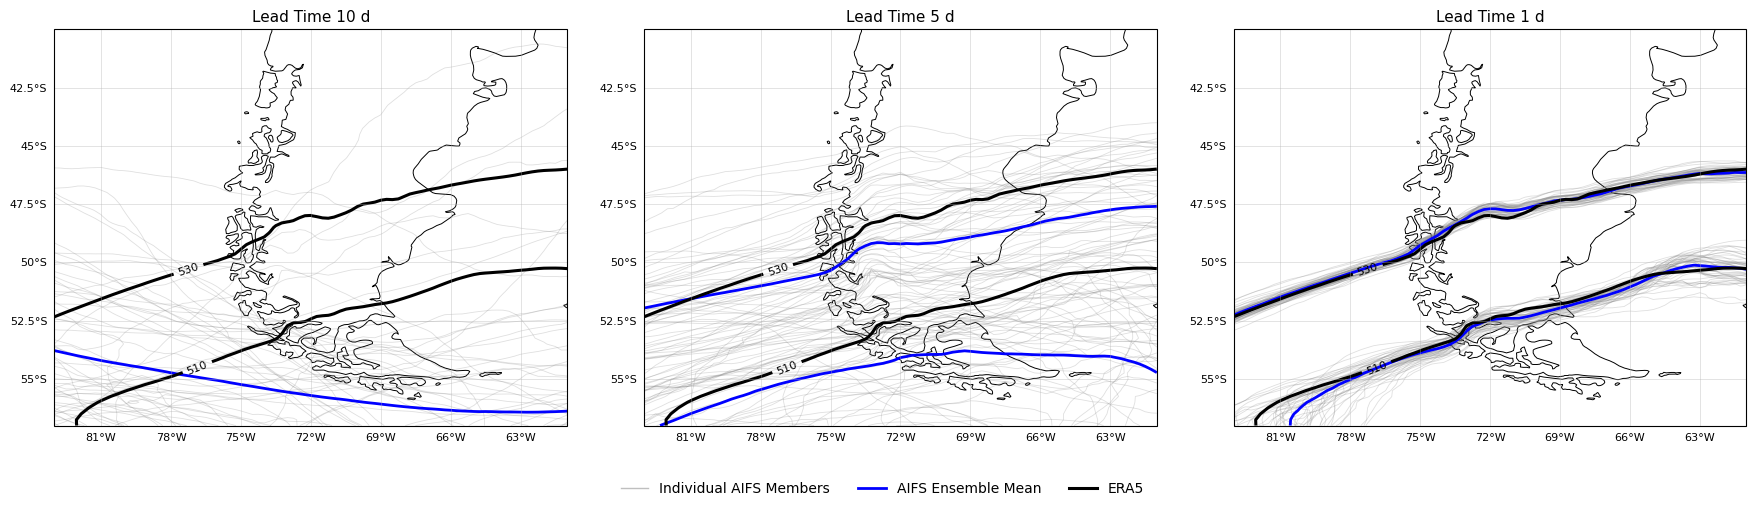

In [22]:
# Individual AIFS ensemble members, AIFS ensemble mean, and ERA5
#
# Thin grey lines: individual AIFS members
# Thick blue lines: AIFS ensemble mean
# Thick black lines: ERA5

# ------------------------------------------------------------------
# Settings
# ------------------------------------------------------------------

selected_leadtimes_spaghetti = [
    10,
    5,
    1
]

z500_contour_levels_spaghetti = [
    510,
    530
]

common_lat_min_spaghetti = -57.0
common_lat_max_spaghetti = -40.0
common_lon_min_spaghetti = 277.0
common_lon_max_spaghetti = 299.0

map_projection = ccrs.PlateCarree()

# ------------------------------------------------------------------
# Select AIFS Z500 on the common domain
# ------------------------------------------------------------------

aifs_Z500_spaghetti = (
    ds_AIFS_pl[
        "geopotential_height_in_dam"
    ]
    .sel(
        isobaricInhPa=500,
        method="nearest"
    )
    .sel(
        latitude=slice(
            common_lat_max_spaghetti,
            common_lat_min_spaghetti
        ),
        longitude=slice(
            common_lon_min_spaghetti,
            common_lon_max_spaghetti
        )
    )
)

# ------------------------------------------------------------------
# Prepare ERA5 Z500
# ------------------------------------------------------------------

era5_Z500_spaghetti = (
    ds_ERA5_pl[
        "geopotential_height_in_dam"
    ]
    .sel(
        isobaricInhPa=500,
        method="nearest"
    )
    .squeeze(drop=True)
    .assign_coords(
        longitude=(
            ds_ERA5_pl[
                "longitude"
            ]
            % 360
        )
    )
    .sortby("latitude")
    .sortby("longitude")
    .sel(
        latitude=slice(
            common_lat_min_spaghetti,
            common_lat_max_spaghetti
        ),
        longitude=slice(
            common_lon_min_spaghetti,
            common_lon_max_spaghetti
        )
    )
)

# ------------------------------------------------------------------
# Create figure
# ------------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5.5),
    subplot_kw={
        "projection": map_projection
    }
)

fig.subplots_adjust(
    left=0.04,
    right=0.98,
    bottom=0.14,
    top=0.90,
    wspace=0.15
)

# ------------------------------------------------------------------
# Spaghetti panels
# ------------------------------------------------------------------

for ax, leadtime_day in zip(
    axes,
    selected_leadtimes_spaghetti
):
    # Select the requested lead time
    aifs_Z500_lead_spaghetti = (
        aifs_Z500_spaghetti.sel(
            leadtime=leadtime_day
        )
    )

    # AIFS ensemble mean
    aifs_Z500_mean_spaghetti = (
        aifs_Z500_lead_spaghetti.mean(
            dim="ensemble_members"
        )
    )

    ax.set_extent(
        [
            common_lon_min_spaghetti,
            common_lon_max_spaghetti,
            common_lat_min_spaghetti,
            common_lat_max_spaghetti
        ],
        crs=map_projection
    )

    # Individual AIFS ensemble members
    for member_index in range(
        aifs_Z500_lead_spaghetti.sizes[
            "ensemble_members"
        ]
    ):
        member_Z500_spaghetti = (
            aifs_Z500_lead_spaghetti.isel(
                ensemble_members=member_index
            )
        )

        ax.contour(
            member_Z500_spaghetti.longitude,
            member_Z500_spaghetti.latitude,
            member_Z500_spaghetti,
            levels=z500_contour_levels_spaghetti,
            colors="grey",
            linewidths=0.6,
            alpha=0.25,
            transform=map_projection
        )

    # AIFS ensemble mean
    ax.contour(
        aifs_Z500_mean_spaghetti.longitude,
        aifs_Z500_mean_spaghetti.latitude,
        aifs_Z500_mean_spaghetti,
        levels=z500_contour_levels_spaghetti,
        colors="blue",
        linewidths=2.0,
        transform=map_projection
    )

    # ERA5
    era5_contours_spaghetti = ax.contour(
        era5_Z500_spaghetti.longitude,
        era5_Z500_spaghetti.latitude,
        era5_Z500_spaghetti,
        levels=z500_contour_levels_spaghetti,
        colors="black",
        linewidths=2.2,
        transform=map_projection
    )

    # Label only the ERA5 contours
    ax.clabel(
        era5_contours_spaghetti,
        inline=True,
        fontsize=8,
        fmt="%d"
    )

    ax.add_feature(
        cfeature.COASTLINE,
        linewidth=0.7
    )

    ax.set_title(
        f"Lead Time {leadtime_day} d",
        fontsize=11
    )

    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.5,
        alpha=0.5
    )

    gl.left_labels = True
    gl.bottom_labels = True
    gl.top_labels = False
    gl.right_labels = False

    gl.xlabel_style = {
        "size": 8
    }

    gl.ylabel_style = {
        "size": 8
    }

# ------------------------------------------------------------------
# Shared legend
# ------------------------------------------------------------------

legend_handles_spaghetti = [
    Line2D(
        [0],
        [0],
        color="grey",
        linewidth=1.0,
        alpha=0.5,
        label="Individual AIFS Members"
    ),
    Line2D(
        [0],
        [0],
        color="blue",
        linewidth=2.0,
        label="AIFS Ensemble Mean"
    ),
    Line2D(
        [0],
        [0],
        color="black",
        linewidth=2.2,
        label="ERA5"
    )
]

fig.legend(
    handles=legend_handles_spaghetti,
    loc="lower center",
    ncol=3,
    fontsize=10,
    frameon=False,
    bbox_to_anchor=(0.5, 0.01)
)

# ------------------------------------------------------------------
# Save and display
# ------------------------------------------------------------------

png_path, pdf_path = save_plot(
    fig,
    "spaghetti_plot_AIFS_ERA5"
)

plt.show()
plt.close(fig)